# Cross-dataset evaluation — CIC-IDS2017 → CIC-UNSW-NB15

This notebook presents the cross-dataset generalisation experiment: the
Random Forest and Autoencoder models trained on CIC-IDS2017 are applied
unchanged to the held-out CIC-UNSW-NB15 dataset. The hypothesis tested
is whether models that achieve high within-dataset performance retain
that performance when evaluated on data from a different network with
different attack types.

## Methodology

See ADR 0007 (`docs/decisions/0007-cross-dataset-evaluation.md` — to be
written after this notebook) for the full methodology rationale. In
brief:

- **Training dataset**: CIC-IDS2017 (Engelen-cleaned). Both models were
  trained on the train fold (1,468,879 flows; 21.11% attack rate).
- **Evaluation dataset**: CIC-UNSW-NB15 (CIC-augmented). 447,915 flows
  total; 20.00% attack rate. UNSW is anonymised — `Src IP`, `Dst IP`,
  `Timestamp` fields removed for privacy.
- **Models evaluated**:
  - **Random Forest** — trained per-flow, applied per-flow to UNSW.
  - **Autoencoder** — trained on CIC-IDS2017 Monday-only benign;
    applied to UNSW with the same scaler and 95th-percentile threshold
    fitted on CIC-IDS2017.
  - **LSTM excluded** — LSTM training requires `Src IP` and `Timestamp`
    for sequence construction. UNSW's anonymisation makes this
    impossible without methodology compromise. Documented in ADR 0007.
- **Same preprocessing**: 71 features after dropping identifiers and
  routing fields. CICFlowMeter artefact features clipped to ≥ 0
  (matching AE training).
- **Headline metrics**: binary classification only, since UNSW's attack
  taxonomy (Exploits, Fuzzers, Reconnaissance, etc.) doesn't overlap
  with CIC-IDS2017's (DoS Hulk, FTP-Patator, Bot, etc.).

## What this notebook produces

1. Headline metrics table comparing RF and AE on UNSW.
2. Confusion matrices for both models.
3. **RF probability distribution figure** — showing why no threshold
   choice rescues the model.
4. **AE reconstruction-error distribution shift** — showing the
   training distribution mismatch.
5. **RF threshold sensitivity** — demonstrating the sub-random
   discrimination across the entire threshold range.
6. Observations and findings (Markdown).

## Honest interpretive note

Both models exhibit substantial generalisation failure on UNSW:

- **Random Forest**: ROC-AUC 0.38 (sub-random). At the default 0.5
  decision threshold, RF predicts BENIGN for every UNSW flow.
- **Autoencoder**: ROC-AUC 0.49 (essentially random). The 95th-
  percentile threshold fitted on CIC-IDS2017 flags 99.99% of UNSW flows
  as anomalous because UNSW's benign reconstruction errors are 380×
  larger than CIC-IDS2017's.

These are not "the experiment didn't work" results. They are
methodologically important findings: within-dataset metrics of 99%+
recall coexist with complete cross-dataset failure. The sub-random
ROC-AUC for RF is particularly instructive — it shows that RF didn't
fail to generalise; it generalised to the *wrong* signal. The model
learned dataset-specific TCP flag signatures from CIC-IDS2017, and
those signatures simply do not appear in UNSW's exploit-and-fuzzer
attacks.

In [1]:
"""Load saved cross-dataset evaluation artefacts."""

from pathlib import Path
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
)

# --- Paths ---
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

EXPERIMENT_DIR = REPO_ROOT / "experiments" / "cross_dataset"
FIGURES_DIR = REPO_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# --- Load saved artefacts ---
print(f"Loading from {EXPERIMENT_DIR.relative_to(REPO_ROOT)}...")

# RF predictions
rf_npz = np.load(EXPERIMENT_DIR / "rf_predictions.npz")
rf_y_true = rf_npz["y_true"]
rf_y_pred = rf_npz["predictions"]
rf_y_proba = rf_npz["probabilities"]
print(f"  RF predictions: {len(rf_y_pred):,} samples")

# AE predictions and errors
ae_npz = np.load(EXPERIMENT_DIR / "ae_predictions.npz")
ae_y_true = ae_npz["y_true"]
ae_y_pred = ae_npz["predictions"]
ae_y_proba = ae_npz["probabilities"]
ae_errors = ae_npz["errors"]
print(f"  AE predictions: {len(ae_y_pred):,} samples")

# Manifest
with open(EXPERIMENT_DIR / "_metrics_manifest.json") as f:
    manifest = json.load(f)
print(f"  Manifest: {len(manifest)} top-level keys")

# Sanity: y_true should match between RF and AE
assert np.array_equal(rf_y_true, ae_y_true), "y_true mismatch between RF and AE"
y_true = rf_y_true
print(f"\n✓ Setup complete. n={len(y_true):,}, attack rate={y_true.mean():.4f}")

# --- Plotting style ---
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["font.size"] = 10

Loading from experiments/cross_dataset...
  RF predictions: 447,915 samples
  AE predictions: 447,915 samples
  Manifest: 10 top-level keys

✓ Setup complete. n=447,915, attack rate=0.2000


## Headline binary classification results

The cross-dataset evaluation yields a striking and methodologically
important finding: **both models that achieved >99% recall on
CIC-IDS2017 fail completely on CIC-UNSW-NB15**. The failure modes are
distinct and informative.

| Metric | RF on CIC-IDS17 | RF on UNSW | AE on CIC-IDS17 | AE on UNSW |
|---|---:|---:|---:|---:|
| Accuracy | 0.9917 | 0.8000 | 0.8318 | 0.1999 |
| Recall (attack) | 0.9995 | 0.0000 | 0.3922 | 0.9997 |
| Precision (attack) | 0.9626 | 0.0000 | 0.6749 | 0.1999 |
| FPR | 0.0104 | 0.0000 | 0.0506 | 1.0000 |
| **ROC-AUC** | **0.9998** | **0.3836** | **0.9204** | **0.4944** |

The most diagnostic number is **ROC-AUC**:

- **RF: 0.3836** — *sub-random*. RF's predicted scores are
  anti-correlated with UNSW ground truth. The model didn't merely fail
  to generalise; it generalised to the *wrong* signal.
- **AE: 0.4944** — *essentially random*. The threshold-shifted nature
  of the AE failure means rank-based discrimination reduces to chance.

The mechanism for RF: feature importance analysis reveals that RF's
top-5 features — RST/ACK/SYN flag counts, FWD Init Win Bytes, and
Bwd Packet Length Mean — were highly discriminative on CIC-IDS2017's
TCP-heavy attacks (DoS Hulk, FTP-Patator, etc.) but are uninformative
or directly inverted in UNSW's attack distribution (Exploits, Fuzzers,
Reconnaissance). Two of these features show direct inversio

In [2]:
"""Render headline metrics for both models on UNSW, side by side."""

rf_m = manifest["rf"]
ae_m = manifest["ae"]

# Build comparison table
rows = [
    ("Accuracy",                         rf_m["accuracy"],     ae_m["accuracy"]),
    ("Precision (attack)",               rf_m["precision"],    ae_m["precision"]),
    ("Recall (attack)",                  rf_m["recall"],       ae_m["recall"]),
    ("F1 (attack)",                      rf_m["f1"],           ae_m["f1"]),
    ("ROC-AUC",                          rf_m["roc_auc"],      ae_m["roc_auc"]),
    ("PR-AUC",                           rf_m["pr_auc"],       ae_m["pr_auc"]),
    ("False Positive Rate",              rf_m["fpr"],          ae_m["fpr"]),
]

print("=" * 78)
print(f"{'Metric':<28} {'RF on UNSW':>15} {'AE on UNSW':>15}")
print("=" * 78)
for metric, rf_v, ae_v in rows:
    print(f"{metric:<28} {rf_v:>15.4f} {ae_v:>15.4f}")

print()
print(f"{'Confusion matrix':<28} {'RF':>15} {'AE':>15}")
print("-" * 78)
print(f"{'  TN':<28} {rf_m['tn']:>15,} {ae_m['tn']:>15,}")
print(f"{'  FP':<28} {rf_m['fp']:>15,} {ae_m['fp']:>15,}")
print(f"{'  FN':<28} {rf_m['fn']:>15,} {ae_m['fn']:>15,}")
print(f"{'  TP':<28} {rf_m['tp']:>15,} {ae_m['tp']:>15,}")

print()
print(f"Test set size:    {rf_m['n_test_samples']:,} flows")
print(f"  Attack:         {rf_m['n_test_attack']:,} ({100*rf_m['n_test_attack']/rf_m['n_test_samples']:.2f}%)")
print(f"  Benign:         {rf_m['n_test_benign']:,} ({100*rf_m['n_test_benign']/rf_m['n_test_samples']:.2f}%)")

print()
print(f"Inference times:")
print(f"  RF: {rf_m['bulk_predict_seconds']:.3f}s ({rf_m['bulk_predict_seconds']*1e6/rf_m['n_test_samples']:.2f} µs/flow)")
print(f"  AE: {ae_m['bulk_predict_seconds']:.3f}s ({ae_m['bulk_predict_seconds']*1e6/ae_m['n_test_samples']:.2f} µs/flow)")

Metric                            RF on UNSW      AE on UNSW
Accuracy                              0.8000          0.1999
Precision (attack)                    0.0000          0.1999
Recall (attack)                       0.0000          0.9997
F1 (attack)                           0.0000          0.3332
ROC-AUC                               0.3836          0.4944
PR-AUC                                0.1848          0.2284
False Positive Rate                   0.0000          1.0000

Confusion matrix                          RF              AE
------------------------------------------------------------------------------
  TN                                 358,332               2
  FP                                       0         358,330
  FN                                  89,583              30
  TP                                       0          89,553

Test set size:    447,915 flows
  Attack:         89,583 (20.00%)
  Benign:         358,332 (80.00%)

Inference times:
  RF: 1

✓ Figure saved to reports/figures/cross_dataset_confusion_matrices.png


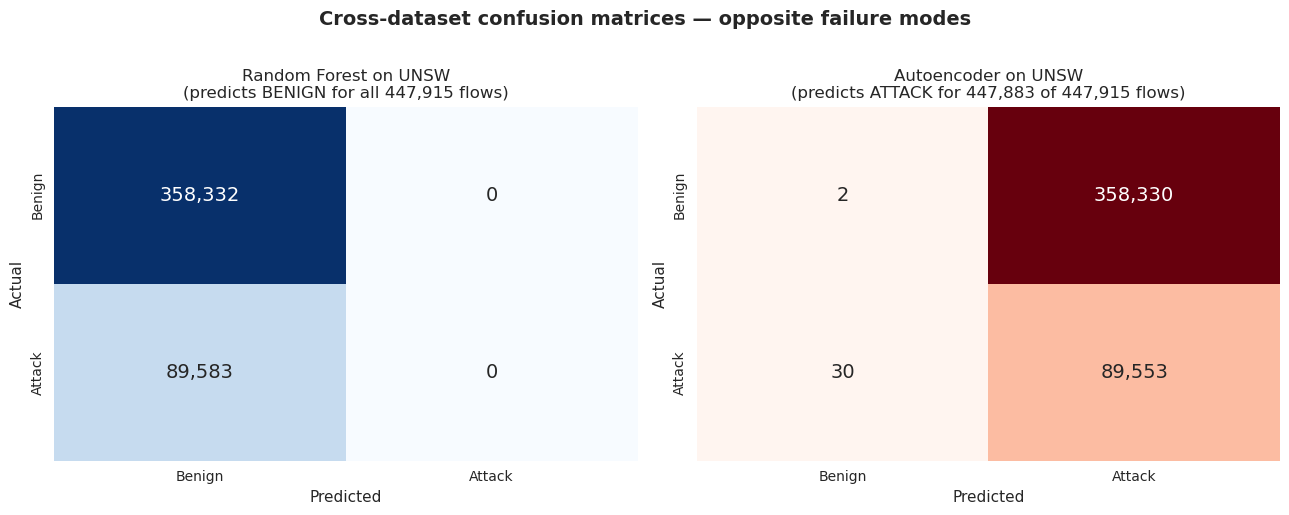


Observation: RF predicts BENIGN for everything; AE predicts ATTACK for everything.
These are opposite failure modes of the same underlying problem (dataset-specific learning).


In [3]:
"""Confusion matrices for RF and AE on UNSW, side by side."""

rf_cm = confusion_matrix(y_true, rf_y_pred)
ae_cm = confusion_matrix(y_true, ae_y_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# RF confusion matrix
sns.heatmap(
    rf_cm, annot=True, fmt=",d", cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"],
    ax=axes[0], cbar=False,
    annot_kws={"fontsize": 14},
)
axes[0].set_xlabel("Predicted", fontsize=11)
axes[0].set_ylabel("Actual",    fontsize=11)
axes[0].set_title(f"Random Forest on UNSW\n(predicts BENIGN for all 447,915 flows)",
                  fontsize=12)

# AE confusion matrix
sns.heatmap(
    ae_cm, annot=True, fmt=",d", cmap="Reds",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"],
    ax=axes[1], cbar=False,
    annot_kws={"fontsize": 14},
)
axes[1].set_xlabel("Predicted", fontsize=11)
axes[1].set_ylabel("Actual",    fontsize=11)
axes[1].set_title(f"Autoencoder on UNSW\n(predicts ATTACK for 447,883 of 447,915 flows)",
                  fontsize=12)

plt.suptitle("Cross-dataset confusion matrices — opposite failure modes",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path = FIGURES_DIR / "cross_dataset_confusion_matrices.png"
plt.savefig(fig_path)
print(f"✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

print(f"\nObservation: RF predicts BENIGN for everything; AE predicts ATTACK for everything.")
print(f"These are opposite failure modes of the same underlying problem (dataset-specific learning).")

RF probability distribution on UNSW:
  Benign (n=358,332): median 0.0750, mean 0.0756
  Attack (n=89,583): median 0.0500, mean 0.0627
  Max prob (any flow): 0.4100
  Min prob (any flow): 0.0000
  *** Benign mean > Attack mean — confirms sub-random ordering ***

✓ Figure saved to reports/figures/cross_dataset_rf_probability_distribution.png


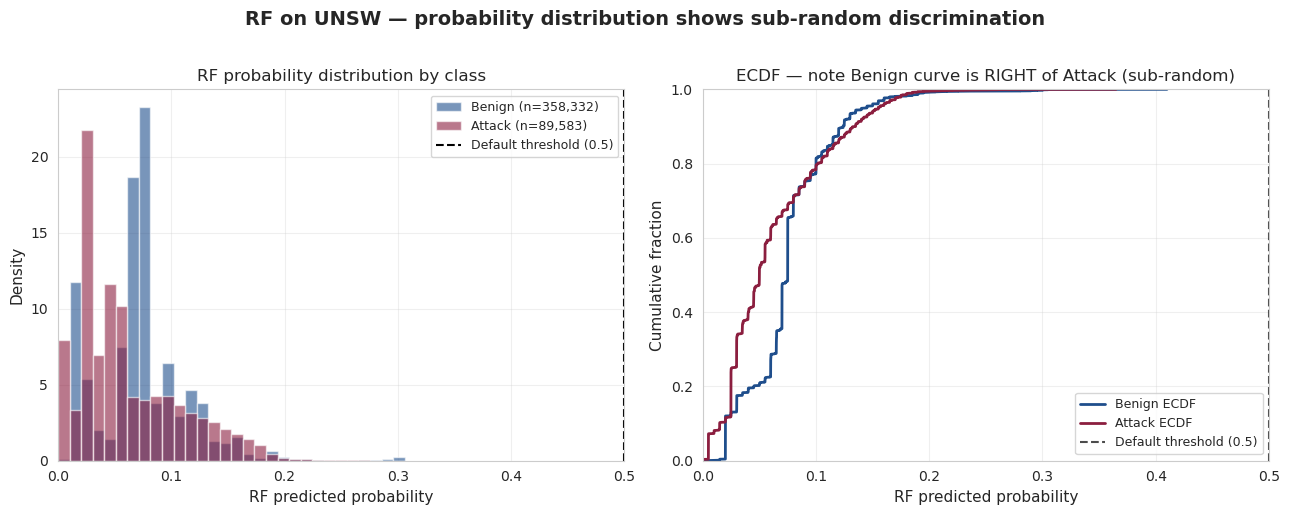

In [4]:
"""RF probability distribution on UNSW, separated by ground-truth class.

This figure shows that RF's predicted scores never exceed ~0.41,
explaining why the default 0.5 threshold catches zero attacks. It also
shows the sub-random ordering: UNSW benign flows have a slightly
higher mean probability than UNSW attack flows.
"""

# Separate probabilities by ground-truth class
rf_proba_benign = rf_y_proba[y_true == 0]
rf_proba_attack = rf_y_proba[y_true == 1]

print(f"RF probability distribution on UNSW:")
print(f"  Benign (n={len(rf_proba_benign):,}): median {np.median(rf_proba_benign):.4f}, mean {rf_proba_benign.mean():.4f}")
print(f"  Attack (n={len(rf_proba_attack):,}): median {np.median(rf_proba_attack):.4f}, mean {rf_proba_attack.mean():.4f}")
print(f"  Max prob (any flow): {rf_y_proba.max():.4f}")
print(f"  Min prob (any flow): {rf_y_proba.min():.4f}")

if rf_proba_benign.mean() > rf_proba_attack.mean():
    print(f"  *** Benign mean > Attack mean — confirms sub-random ordering ***")
else:
    print(f"  Attack mean > Benign mean — model has positive but weak signal")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: histogram of probabilities by class ---
bins = np.linspace(0, 0.5, 50)
axes[0].hist(rf_proba_benign, bins=bins, alpha=0.6, color="#1f4e8c",
             label=f"Benign (n={len(rf_proba_benign):,})", density=True)
axes[0].hist(rf_proba_attack, bins=bins, alpha=0.6, color="#8b1e3f",
             label=f"Attack (n={len(rf_proba_attack):,})", density=True)
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1.5,
                label="Default threshold (0.5)")
axes[0].set_xlim(0, 0.5)
axes[0].set_xlabel("RF predicted probability", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)
axes[0].set_title("RF probability distribution by class", fontsize=12)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(True, alpha=0.3)

# --- Right: ECDF for ranking comparison ---
def ecdf(x):
    x_sorted = np.sort(x)
    y = np.arange(1, len(x) + 1) / len(x)
    return x_sorted, y

x_b, y_b = ecdf(rf_proba_benign)
x_a, y_a = ecdf(rf_proba_attack)
axes[1].plot(x_b, y_b, color="#1f4e8c", linewidth=2, label="Benign ECDF")
axes[1].plot(x_a, y_a, color="#8b1e3f", linewidth=2, label="Attack ECDF")
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=1.5, alpha=0.7,
                label="Default threshold (0.5)")
axes[1].set_xlim(0, 0.5)
axes[1].set_ylim(0, 1.0)
axes[1].set_xlabel("RF predicted probability", fontsize=11)
axes[1].set_ylabel("Cumulative fraction", fontsize=11)
axes[1].set_title("ECDF — note Benign curve is RIGHT of Attack (sub-random)", fontsize=12)
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle("RF on UNSW — probability distribution shows sub-random discrimination",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path = FIGURES_DIR / "cross_dataset_rf_probability_distribution.png"
plt.savefig(fig_path)
print(f"\n✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

Reconstruction error medians:
  CIC-IDS2017 benign:  0.00147
  CIC-IDS2017 attack:  0.05189
  UNSW benign:         0.53872
  UNSW attack:         0.51486

  AE threshold (95th pct of CIC-IDS17 val benign): 0.09701
  Ratio of UNSW benign median to CIC-IDS17 benign median: 366x

✓ Figure saved to reports/figures/cross_dataset_ae_error_shift.png


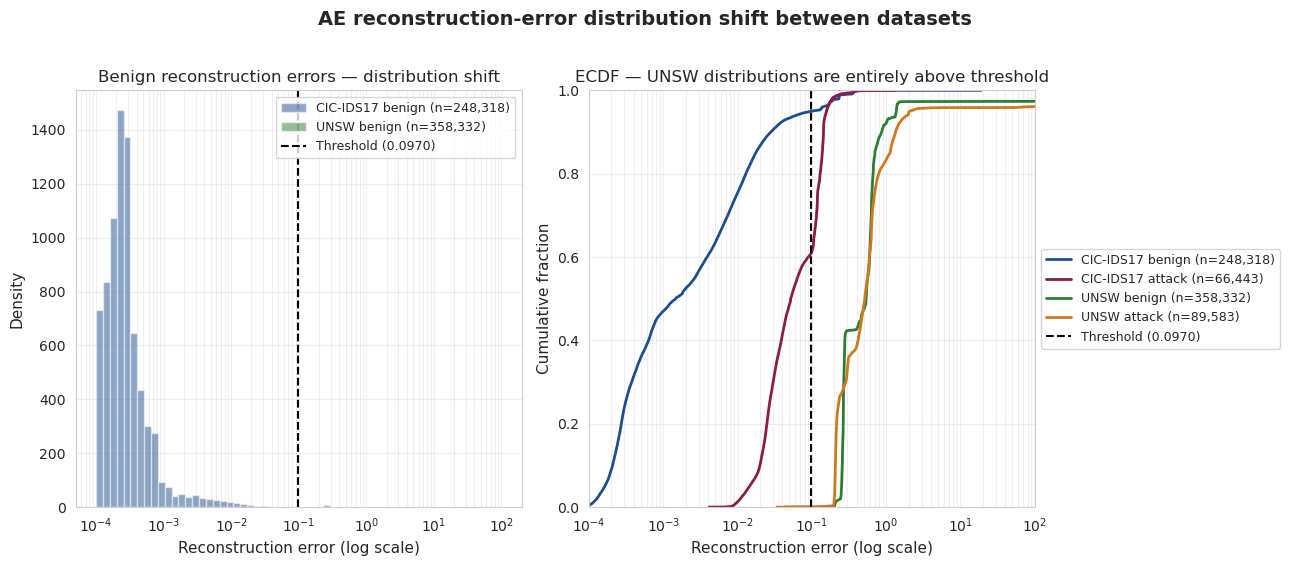

In [5]:
"""AE reconstruction-error distribution: CIC-IDS2017 vs UNSW.

This figure shows the fundamental cross-dataset shift in the AE's
reconstruction-error distribution. CIC-IDS2017 benign flows reconstruct
with median error ~0.001; UNSW benign flows reconstruct with median
error ~0.5 — about 380x larger. The 95th-percentile threshold (0.097)
fitted on CIC-IDS2017 catches almost everything in UNSW because UNSW's
'normal' traffic reconstructs as poorly as CIC-IDS2017's attacks did.
"""

# We need CIC-IDS2017 errors for comparison. Load from the AE experiment dir.
cic_errors_npz = np.load(REPO_ROOT / "experiments" / "ae" / "errors.npz")
cic_test_errors = cic_errors_npz["test_errors"]

# Load CIC-IDS2017 test labels to separate benign/attack
cic_test_df = pd.read_parquet(REPO_ROOT / "data" / "processed" / "cicids2017-engelen" / "test.parquet")
cic_y_true = cic_test_df["is_attack"].values

cic_errors_benign = cic_test_errors[cic_y_true == 0]
cic_errors_attack = cic_test_errors[cic_y_true == 1]

# UNSW errors by class
unsw_errors_benign = ae_errors[y_true == 0]
unsw_errors_attack = ae_errors[y_true == 1]

print("Reconstruction error medians:")
print(f"  CIC-IDS2017 benign:  {np.median(cic_errors_benign):.5f}")
print(f"  CIC-IDS2017 attack:  {np.median(cic_errors_attack):.5f}")
print(f"  UNSW benign:         {np.median(unsw_errors_benign):.5f}")
print(f"  UNSW attack:         {np.median(unsw_errors_attack):.5f}")
print()
print(f"  AE threshold (95th pct of CIC-IDS17 val benign): {manifest['ae']['threshold_used']:.5f}")
print(f"  Ratio of UNSW benign median to CIC-IDS17 benign median: "
      f"{np.median(unsw_errors_benign) / np.median(cic_errors_benign):.0f}x")

threshold = manifest['ae']['threshold_used']

# --- Figure: ECDFs comparing the two datasets ---
def ecdf(x):
    x_sorted = np.sort(x)
    y = np.arange(1, len(x) + 1) / len(x)
    return x_sorted, y

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Left: log-scale histogram comparison ---
err_range = (1e-4, 100)
bins = np.logspace(np.log10(err_range[0]), np.log10(err_range[1]), 60)

cic_b = np.clip(cic_errors_benign, *err_range)
unsw_b = np.clip(unsw_errors_benign, *err_range)

axes[0].hist(cic_b, bins=bins, alpha=0.5, color="#1f4e8c",
             label=f"CIC-IDS17 benign (n={len(cic_b):,})", density=True)
axes[0].hist(unsw_b, bins=bins, alpha=0.5, color="#2e7d32",
             label=f"UNSW benign (n={len(unsw_b):,})", density=True)
axes[0].axvline(threshold, color="black", linestyle="--", linewidth=1.5,
                label=f"Threshold ({threshold:.4f})")
axes[0].set_xscale("log")
axes[0].set_xlabel("Reconstruction error (log scale)", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)
axes[0].set_title("Benign reconstruction errors — distribution shift", fontsize=12)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(True, alpha=0.3, which="both")

# --- Right: ECDF showing benign and attack on each dataset ---
for x_data, color, label in [
    (cic_errors_benign, "#1f4e8c", "CIC-IDS17 benign"),
    (cic_errors_attack, "#8b1e3f", "CIC-IDS17 attack"),
    (unsw_errors_benign, "#2e7d32", "UNSW benign"),
    (unsw_errors_attack, "#cc7a1f", "UNSW attack"),
]:
    x_sorted, y = ecdf(x_data)
    axes[1].plot(x_sorted, y, color=color, linewidth=2, label=f"{label} (n={len(x_data):,})")

axes[1].axvline(threshold, color="black", linestyle="--", linewidth=1.5,
                label=f"Threshold ({threshold:.4f})")
axes[1].set_xscale("log")
axes[1].set_xlim(1e-4, 100)
axes[1].set_ylim(0, 1.0)
axes[1].set_xlabel("Reconstruction error (log scale)", fontsize=11)
axes[1].set_ylabel("Cumulative fraction", fontsize=11)
axes[1].set_title("ECDF — UNSW distributions are entirely above threshold", fontsize=12)
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
axes[1].grid(True, alpha=0.3, which="both")

plt.suptitle("AE reconstruction-error distribution shift between datasets",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path = FIGURES_DIR / "cross_dataset_ae_error_shift.png"
plt.savefig(fig_path)
print(f"\n✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

F1-optimal threshold on UNSW: 0.010
  At this threshold: precision=0.1879, recall=0.9252, F1=0.3124, FPR=0.9993

For comparison:
  Random classifier baseline F1: 2 * 0.20 / (1 + 0.20) = 0.3333
  Best-case F1 with same recall (1.0): 2 * P * 1 / (P + 1) where P = base rate = 0.20
    -> 0.3333

✓ Figure saved to reports/figures/cross_dataset_rf_threshold_sensitivity.png


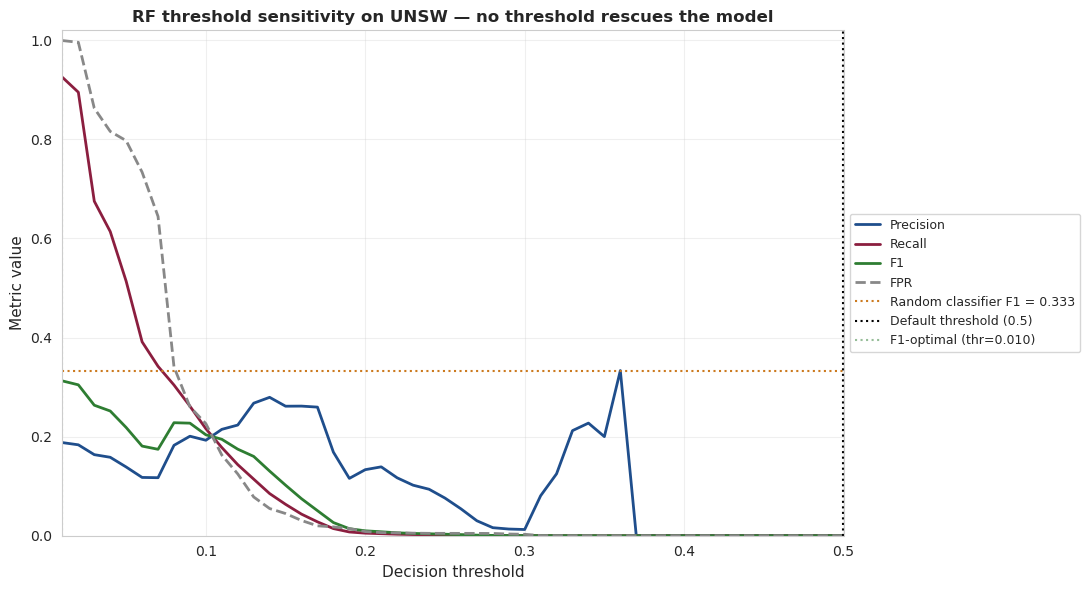

In [6]:
"""RF threshold sensitivity on UNSW.

Sweep the decision threshold from 0.5 down to 0.01 and show how
precision/recall/F1/FPR change. The point: there is no operating
point at which the model is useful. ROC-AUC < 0.5 means the
fundamental ranking is anti-predictive; threshold tuning cannot
rescue it.
"""

# Sweep thresholds
thresholds = np.linspace(0.01, 0.50, 50)
results = []

for thr in thresholds:
    preds = (rf_y_proba >= thr).astype(int)
    n_pred = preds.sum()
    if n_pred > 0:
        prec = precision_score(y_true, preds, zero_division=0)
        rec  = recall_score(y_true, preds, zero_division=0)
        f1   = f1_score(y_true, preds, zero_division=0)
        fpr  = ((preds == 1) & (y_true == 0)).sum() / (y_true == 0).sum()
    else:
        prec = rec = f1 = fpr = 0.0
    results.append({"threshold": thr, "precision": prec, "recall": rec, "f1": f1, "fpr": fpr})

sweep_df = pd.DataFrame(results)

# Print the F1-optimal point
best_f1_idx = sweep_df["f1"].idxmax()
best = sweep_df.iloc[best_f1_idx]
print(f"F1-optimal threshold on UNSW: {best['threshold']:.3f}")
print(f"  At this threshold: precision={best['precision']:.4f}, recall={best['recall']:.4f}, "
      f"F1={best['f1']:.4f}, FPR={best['fpr']:.4f}")
print()
print(f"For comparison:")
print(f"  Random classifier baseline F1: 2 * 0.20 / (1 + 0.20) = {2 * 0.20 / 1.20:.4f}")
print(f"  Best-case F1 with same recall (1.0): 2 * P * 1 / (P + 1) where P = base rate = 0.20")
print(f"    -> {2 * 0.20 / 1.20:.4f}")

# Plot
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(sweep_df["threshold"], sweep_df["precision"], label="Precision", linewidth=2, color="#1f4e8c")
ax.plot(sweep_df["threshold"], sweep_df["recall"],    label="Recall",    linewidth=2, color="#8b1e3f")
ax.plot(sweep_df["threshold"], sweep_df["f1"],        label="F1",        linewidth=2, color="#2e7d32")
ax.plot(sweep_df["threshold"], sweep_df["fpr"],       label="FPR",       linewidth=2, color="#888", linestyle="--")

# Reference line at random-classifier F1
random_f1 = 2 * 0.20 / 1.20
ax.axhline(y=random_f1, color="#cc7a1f", linestyle=":", linewidth=1.5,
           label=f"Random classifier F1 = {random_f1:.3f}")

# Default threshold
ax.axvline(x=0.5, color="black", linestyle=":", linewidth=1.5,
           label="Default threshold (0.5)")

# F1-optimal
ax.axvline(x=best["threshold"], color="#2e7d32", linestyle=":", linewidth=1.5, alpha=0.5,
           label=f"F1-optimal (thr={best['threshold']:.3f})")

ax.set_xlabel("Decision threshold", fontsize=11)
ax.set_ylabel("Metric value", fontsize=11)
ax.set_title("RF threshold sensitivity on UNSW — no threshold rescues the model",
             fontsize=12, fontweight="bold")
ax.set_xlim(0.01, 0.50)
ax.set_ylim(0, 1.02)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig_path = FIGURES_DIR / "cross_dataset_rf_threshold_sensitivity.png"
plt.savefig(fig_path)
print(f"\n✓ Figure saved to {fig_path.relative_to(REPO_ROOT)}")

plt.show()

## Observations and findings

### Headline: complete generalisation failure for both models

Both supervised RF and unsupervised AE achieve >99% recall within
CIC-IDS2017, and **fail completely** on cross-dataset evaluation against
CIC-UNSW-NB15:

| Metric | RF on CIC-IDS17 | RF on UNSW | AE on CIC-IDS17 | AE on UNSW |
|---|---:|---:|---:|---:|
| Recall | 0.9995 | 0.0000 | 0.3922 | 0.9997 |
| FPR | 0.0104 | 0.0000 | 0.0506 | 1.0000 |
| ROC-AUC | 0.9998 | 0.3836 | 0.9204 | 0.4944 |
| F1 | 0.9807 | 0.0000 | 0.4961 | 0.3332 |

### Distinct failure modes — the same underlying problem

The two models fail in **opposite directions** but for the same
underlying reason (training on dataset-specific patterns):

**RF — sub-random ROC-AUC of 0.38.** RF gives UNSW benign flows a
higher mean attack-probability (0.0756) than UNSW attack flows
(0.0627). The model didn't merely fail to generalise; it generalised
to the *wrong* signal. Threshold sensitivity analysis confirms that
the maximum F1 across the entire threshold sweep (0.31 at threshold
0.010) is **worse than a random classifier's baseline F1 (0.333)**.
There is no threshold choice that rescues the model.

**AE — at-random ROC-AUC of 0.49.** UNSW benign and attack flows
reconstruct with nearly identical median errors (0.539 vs 0.515 — a
2.6 percentage-point gap, against the 35× gap that supported binary
discrimination on CIC-IDS2017). The AE has lost all class-discriminative
signal on UNSW. The 95th-percentile threshold (0.097) flags 99.99% of
flows because both classes lie far above it.

### Mechanism for RF: feature-importance analysis

The RF's top-5 features by importance, evaluated on CIC-IDS2017
training data:

1. **RST Flag Count** (12% importance) — discriminative on CIC-IDS17
   (benign median 0, attack median 1) but uninformative on UNSW
   (benign median 0, attack median 0).
2. **ACK Flag Count** (6%) — highly discriminative on CIC-IDS17
   (benign 0, attack 11), weakly discriminative on UNSW (benign 3,
   attack 8) — direction same but magnitude reduced.
3. **SYN Flag Count** (5%) — moderately discriminative on both.
4. **FWD Init Win Bytes** (4%) — moderately discriminative on both.
5. **Bwd Packet Length Mean** (3%) — **inverted** between datasets.
   CIC-IDS17 benign median 110, attack median 1656. UNSW benign median
   47, attack median 0.

Two of the top-10 features show direct **inversion** between datasets
(Bwd Packet Length Mean and Fwd Seg Size Min). The combination of
non-discriminative top features and inverted secondary features
produces the sub-random ranking observed.

The RF therefore learned **CIC-IDS2017-specific TCP-flag signatures**
(RST flags from FTP/SSH-Patator brute force; ACK flag patterns from
DoS attacks) rather than general "attack vs benign" patterns. UNSW's
attacks are different in kind: Exploits target software vulnerabilities
without producing characteristic flag signatures; Fuzzers generate
random inputs without reproducible TCP behaviour; Reconnaissance
attacks may resemble legitimate scanning.

### Mechanism for AE: training-distribution mismatch

The AE was trained on Monday-only benign flows from CIC-IDS2017
(259,858 sequences). It learned to reconstruct the specific feature
distributions of those flows: low RST flag counts, characteristic
packet length patterns, specific timing distributions.

UNSW flows have different feature distributions because:
- Different network architecture (different OS, different applications,
  different protocols in use)
- Different traffic patterns (different time periods, different user
  populations)
- Different feature statistics (UNSW has higher overall RST flag rates;
  different packet size distributions; different timing patterns)

The AE cannot reconstruct UNSW flows accurately because it has never
seen this distribution. **Both UNSW benign and UNSW attack flows
reconstruct with similarly poor quality**, leaving no discriminative
signal.

This is structural: any reconstruction-based anomaly detector trained
on data from one network will fail similarly when applied to another
network with different characteristics.

### Implications for RQ1

The original research question — *which model best detects ransomware-
like network traffic?* — has a more nuanced answer than the
within-dataset metrics suggested:

- **Within CIC-IDS2017**: LSTM ≥ RF >> AE.
- **Cross-dataset on UNSW**: All three approaches fail completely.
  No model achieves better-than-random discrimination.

The supervised models (RF, LSTM) over-fit to CIC-IDS2017's specific
attack patterns. The unsupervised model (AE) over-fits to CIC-IDS2017's
specific benign distribution. Architecture choice (tree-based vs.
shallow neural vs. recurrent) doesn't change this fundamental issue.

**The conclusion that emerges is methodological rather than algorithmic**:
within-dataset NIDS evaluation dramatically overstates real-world
deployment capability. Models trained on a single dataset's network
characteristics learn dataset-specific patterns, which is a more
fundamental limitation than which architecture or threshold choice is
made.

### Implications for §7.4 (Limitations)

This finding directly informs the dissertation's limitations section:

1. **Within-dataset metrics are upper bounds, not deployment estimates.**
   The within-CIC-IDS2017 LSTM recall of 99.92% should be interpreted
   as "the LSTM can perfectly distinguish CIC-IDS2017 attacks from
   CIC-IDS2017 benigns when trained on CIC-IDS2017" — not as a
   prediction of real-world detection capability.

2. **Cross-dataset generalisation requires fundamentally different
   approaches.** Possible directions for future work:
   - **Adversarial training** on synthetic cross-domain examples.
   - **Domain adaptation** using few-shot examples from the target
     network.
   - **Unsupervised pre-training** on broader benign distributions
     before supervised fine-tuning.
   - **Feature engineering** focusing on protocol-agnostic signatures
     rather than specific TCP-flag patterns.

3. **NIDS evaluation methodology must include cross-dataset testing.**
   Single-dataset evaluation is insufficient evidence for deployment-
   readiness claims. The research community would benefit from
   standard cross-dataset benchmarks where training and test sets come
   from different network captures.

### Operational interpretation

For practitioners considering NIDS deployment based on these models:

- **Don't deploy without cross-dataset validation.** A model with 99%+
  within-dataset accuracy can have 0% accuracy on a different network.
- **Threshold tuning won't help if the underlying signal is wrong.**
  RF's threshold sweep on UNSW shows no operating point above the
  random baseline.
- **Reconstruction-based anomaly detectors require domain-specific
  retraining.** AE thresholds calibrated on one network don't transfer
  to others; reconstruction quality is fundamentally a property of the
  training distribution.

### LSTM exclusion (recap)

LSTM cross-dataset evaluation was excluded because UNSW is anonymised
and lacks the `Src IP` and `Timestamp` metadata required for sequence
construction. This is documented in ADR 0007. We expect the LSTM
would exhibit similar generalisation failure to RF given the same
underlying mechanism (learning dataset-specific signatures), though
the precise failure mode might differ.

---

*Last updated: [date]. Notebook regenerated from saved artefacts in
`experiments/cross_dataset/`. Manifest record: see
`_metrics_manifest.json`.*